<a href="https://colab.research.google.com/github/jofagan/Football-Analysis/blob/main/Football_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics supervision roboflow

In [ ]:
import torch
print(torch.cuda.is_available(),torch.cuda.get_device_name(0))

True Tesla T4


In [ ]:
from google.colab import drive
drive.mount("/content/drive") # mount google drive so project survives when colab resets

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
from google.colab import userdata
ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

In [39]:
#get roboflow dataset in yolov8 format
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
version = project.version(20)
dataset = version.download("yolov8")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...
/content/football-players-detection-20


In [ ]:
#check the class names
!cat {dataset.location}/data.yaml

names:
- ball
- goalkeeper
- player
- referee
nc: 4
roboflow:
  license: CC BY 4.0
  project: football-players-detection-3zvbc
  url: https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/dataset/20
  version: 20
  workspace: roboflow-jvuqo
test: ../test/images
train: ../train/images
val: ../valid/images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#train the detector
from ultralytics import YOLO

model = YOLO("yolo11m.pt")

model.train(
    data = f"{dataset.location}/data.yaml",
    epochs = 60,
    imgsz = 1280,
    batch = 6,
    plots = True
)
!cp runs/detect/train/weights/best.pt /content/drive/MyDrive/soccer_best.pt

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football-players-detection-20/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, opti

In [ ]:
#check how well it learned
metrics = YOLO("runs/detect/train/weights/best.pt").val(data=f"{dataset.location}/data.yaml", imgsz=1280)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,033,116 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2231.9±742.0 MB/s, size: 49.0 KB)
val: Scanning /content/football-players-detection-20/valid/labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 12.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0s/it 8.1s
                   all         49       1174      0.913      0.883      0.892      0.598
                  ball         45         45      0.877      0.689      0.697      0.327
            goalkeeper         38         39      0.856      0.912      0.901      0.664
                player         49        973      0.974      0.984      0.994       0.76
               referee         49        117      0.946      0.949      0.975       0.64
Speed: 23.6ms preprocess, 

In [ ]:
import supervision as sv
from ultralytics import YOLO

SOURCE = "/match.mp4"
TARGET = "match_tracked.mp4"

model = YOLO("/content/drive/MyDrive/soccer_best.pt")
BALL_ID = [k for k, v in model.names.items() if v == "ball"][0]

tracker = sv.ByteTrack()
ellipse = sv.EllipseAnnotator(thickness=2)
labeler = sv.LabelAnnotator(text_position=sv.Position.BOTTOM_CENTER,
    text_scale=0.5,
    text_padding=3,
    smart_position=True,)   # nudges labels apart when they overlap (newer supervision versions))
triangle = sv.TriangleAnnotator(color=sv.Color.from_hex("#FFD700"), base=20, height=17)

video_info = sv.VideoInfo.from_video_path(SOURCE)

with sv.VideoSink(TARGET, video_info) as sink:
    for frame in sv.get_video_frames_generator(SOURCE):
        result = model(frame, imgsz=1280, conf=0.1, verbose=False)[0]
        detections = sv.Detections.from_ultralytics(result)

        # The ball: keep only the most confident detection and don't track it
        ball = detections[(detections.class_id == BALL_ID) & (detections.confidence > 0.1)]
        if len(ball) > 1:
            ball = ball[[ball.confidence.argmax()]]
        ball.xyxy = sv.pad_boxes(xyxy=ball.xyxy, px=10)

        # People: remove duplicate boxes, then assign tracking IDs
        people = detections[(detections.class_id != BALL_ID) & (detections.confidence > 0.3)]
        people = people.with_nms(threshold=0.5, class_agnostic=True)
        people = tracker.update_with_detections(people)

        labels = [f"#{tid}" for tid in people.tracker_id]

        annotated = frame.copy()
        annotated = ellipse.annotate(annotated, people)
        annotated = labeler.annotate(annotated, people, labels=labels)
        annotated = triangle.annotate(annotated, ball)
        sink.write_frame(annotated)

print("Done:", TARGET)

Done: match_tracked.mp4


### COLOUR EVERY PLAYER BY TEAM AUTOMATICALLY
1. Collect shirt colors from players across a sample of frames.
2. Cluster them into two groups with k-means. Each group is a team. No labeling or training needed.
3. In the video loop, measure each player’s shirt color and assign the closer team.
4. Smooth it per tracking ID, so a player doesn’t flicker between teams when shadows or overlaps confuse one frame.
5. Goalkeepers wear different colors from their teammates, so assign each to the team whose players are closest to him.
6. Referees keep their own color.

In [ ]:
import cv2
import numpy as np
import supervision as sv
from ultralytics import YOLO
from sklearn.cluster import KMeans
from collections import defaultdict, deque, Counter

SOURCE = "/match.mp4"
model = YOLO("/content/drive/MyDrive/soccer_best.pt")

name_to_id = {v: k for k, v in model.names.items()}
BALL_ID = name_to_id["ball"]
PLAYER_ID = name_to_id["player"]
GK_ID = name_to_id["goalkeeper"]
REF_ID = name_to_id["referee"]


def jersey_color(frame, box):
    """Median shirt color of a player, ignoring grass pixels. Returns a LAB color or None."""
    h_img, w_img = frame.shape[:2]
    x1, y1, x2, y2 = box.astype(int)
    x1, x2 = np.clip([x1, x2], 0, w_img)
    y1, y2 = np.clip([y1, y2], 0, h_img)
    h, w = y2 - y1, x2 - x1
    if h < 10 or w < 5:
        return None

    # Torso only: skip the head, shorts, and legs, and trim the sides
    crop = frame[y1 + int(0.15 * h): y1 + int(0.5 * h),
                 x1 + int(0.25 * w): x2 - int(0.25 * w)]
    if crop.size == 0:
        return None

    # Remove grass-green pixels
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    grass = cv2.inRange(hsv, (40, 40, 40), (85, 255, 255))
    pixels = crop[grass == 0]
    if len(pixels) < 10:
        pixels = crop.reshape(-1, 3)

    lab = cv2.cvtColor(pixels.reshape(-1, 1, 3).astype(np.uint8), cv2.COLOR_BGR2LAB)
    return np.median(lab.reshape(-1, 3), axis=0)


def resolve_goalkeepers(players, goalkeepers):
    """Assign each goalkeeper to the team whose players are closest on average."""
    if len(goalkeepers) == 0:
        return np.array([], dtype=int)
    gk_xy = goalkeepers.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    p_xy = players.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
    centroids = []
    for team in (0, 1):
        pts = p_xy[players.class_id == team]
        centroids.append(pts.mean(axis=0) if len(pts) else np.array([np.inf, np.inf]))
    dists = np.linalg.norm(gk_xy[:, None, :] - np.array(centroids)[None, :, :], axis=2)
    return dists.argmin(axis=1)

In [29]:
# learn the two teams colours
features, crops = [], []

for frame in sv.get_video_frames_generator(SOURCE, stride=30):   # every 30th frame
    result = model(frame, imgsz=1280, conf=0.3, verbose=False)[0]
    dets = sv.Detections.from_ultralytics(result)
    dets = dets[dets.class_id == PLAYER_ID]
    for box in dets.xyxy:
        f = jersey_color(frame, box)
        if f is not None:
            features.append(f)
            crops.append(sv.crop_image(frame, box))

features = np.array(features)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit(features)
def lab_to_hex(lab):
    lab = np.clip(np.round(lab), 0, 255).astype(np.uint8)
    b, g, r = cv2.cvtColor(lab.reshape(1, 1, 3), cv2.COLOR_LAB2BGR)[0, 0]
    return f"#{r:02X}{g:02X}{b:02X}"

team_hex = [lab_to_hex(c) for c in kmeans.cluster_centers_]
print(team_hex)
COLORS = sv.ColorPalette.from_hex(team_hex + ["#FFFFFF"])   # team 0, team 1, referee
print(f"{len(features)} player crops collected")

['#C2E246', '#484D76']
507 player crops collected


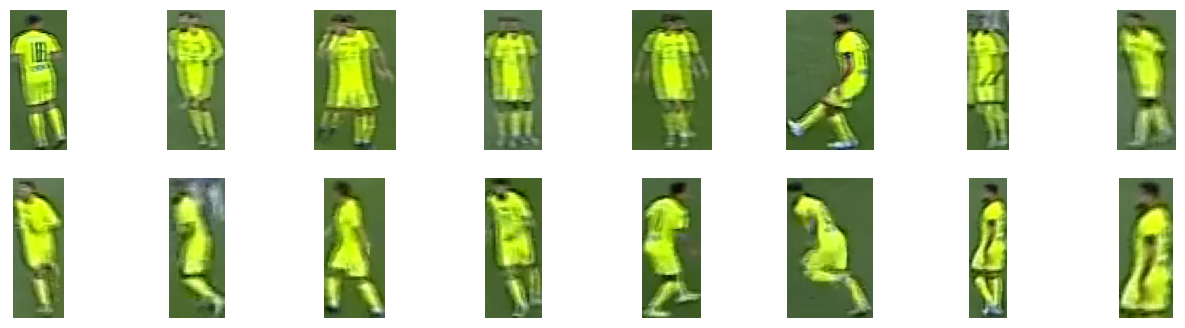

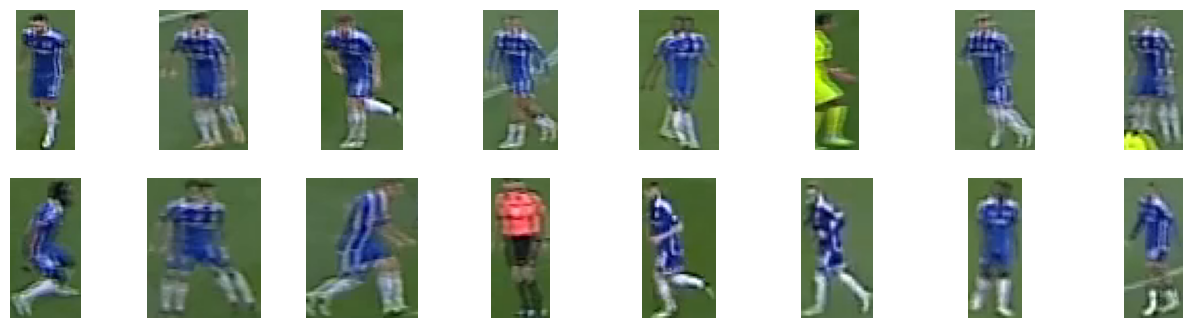

In [30]:
#check that the clusters are the two teams
labels = kmeans.labels_
for team in (0, 1):
    sample = [c for c, l in zip(crops, labels) if l == team][:16]
    sv.plot_images_grid(sample, grid_size=(2, 8), size=(16, 4))

In [31]:
from tqdm import tqdm

TARGET = "match_teams.mp4"

# Colors: team 0, team 1, referee. Swap the first two if they don't match the kits.


tracker = sv.ByteTrack()
ellipse = sv.EllipseAnnotator(color=COLORS, thickness=2)
labeler = sv.LabelAnnotator(
    color=COLORS,
    text_color=sv.Color.BLACK,
    text_position=sv.Position.BOTTOM_CENTER,
    text_scale=0.5,
    text_padding=3,
    smart_position=True,
)
triangle = sv.TriangleAnnotator(color=sv.Color.from_hex("#FF1493"), base=20, height=17)

team_votes = defaultdict(lambda: deque(maxlen=30))   # last 30 team guesses per tracking ID

video_info = sv.VideoInfo.from_video_path(SOURCE)
frames = sv.get_video_frames_generator(SOURCE)

with sv.VideoSink(TARGET, video_info) as sink:
    for frame in tqdm(frames, total=video_info.total_frames):
        result = model(frame, imgsz=1280, conf=0.1, verbose=False)[0]
        detections = sv.Detections.from_ultralytics(result)

        # Ball
        ball = detections[(detections.class_id == BALL_ID) & (detections.confidence > 0.1)]
        if len(ball) > 1:
            ball = ball[[ball.confidence.argmax()]]
        ball.xyxy = sv.pad_boxes(xyxy=ball.xyxy, px=10)

        # People: filter, remove duplicates, track
        people = detections[(detections.class_id != BALL_ID) & (detections.confidence > 0.3)]
        people = people.with_nms(threshold=0.5, class_agnostic=True)
        people = tracker.update_with_detections(people)

        players = people[people.class_id == PLAYER_ID]
        goalkeepers = people[people.class_id == GK_ID]
        referees = people[people.class_id == REF_ID]

        # Team for each player: this frame's guess, smoothed by recent history
        frame_feats, idx = [], []
        for i, box in enumerate(players.xyxy):
            f = jersey_color(frame, box)
            if f is not None:
                frame_feats.append(f)
                idx.append(i)
        if frame_feats:
            preds = kmeans.predict(np.array(frame_feats))
            for i, p in zip(idx, preds):
                team_votes[players.tracker_id[i]].append(int(p))

        players.class_id = np.array(
            [Counter(team_votes[t]).most_common(1)[0][0] if team_votes[t] else 0
             for t in players.tracker_id],
            dtype=int,
        )
        goalkeepers.class_id = resolve_goalkeepers(players, goalkeepers)
        referees.class_id = np.full(len(referees), 2, dtype=int)

        people = sv.Detections.merge([players, goalkeepers, referees])
        labels = (
            [f"#{tid}" for tid in people.tracker_id]
            if people.tracker_id is not None
            else []
                )

        annotated = frame.copy()
        annotated = ellipse.annotate(annotated, people)
        annotated = labeler.annotate(annotated, people, labels=labels)
        annotated = triangle.annotate(annotated, ball)
        sink.write_frame(annotated)

print("Done:", TARGET)

100%|██████████| 1855/1855 [02:43<00:00, 11.34it/s]

Done: match_teams.mp4
